<a href="https://colab.research.google.com/github/WongQiYang-2026/data-science-toolkit/blob/main/Tutorial_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [353]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In this project, I would like to focus on students' grade

In [354]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Dataset/Student Performance.csv')
display(df.head())

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


2. Evaluate if the data is good or not. Does it have enough samples?

In [355]:
print("Rows and colums:", df.shape)
print("Repeated StudentID Values:", df["StudentID"].duplicated().sum())
print("GradeClass (0 = A, 1 = B, 2 = C, 3 = D, 4 = F)")
print(df["GradeClass"].value_counts())

Rows and colums: (2392, 15)
Repeated StudentID Values: 0
GradeClass (0 = A, 1 = B, 2 = C, 3 = D, 4 = F)
GradeClass
4.0    1211
3.0     414
2.0     391
1.0     269
0.0     107
Name: count, dtype: int64


The data is a good data as it has enough observation, features and target (GradeClass) that enable us to determine the grade of students.

3.How many features does it have? Is it enough?

In [356]:
print("All Columns:")
print(df.columns.tolist())
print("Number of columns:", len(df.columns))
print("Number of features(Excluding GradeClass):", len(df.columns)-1)

All Columns:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']
Number of columns: 15
Number of features(Excluding GradeClass): 14


There are 14 features with 1 output(GradeClass) which indicate students' grade

4. How many samples/observation does it have? Is it enough?

In [357]:
print("Number of observation:", len(df))

Number of observation: 2392


This dataset has 2392 observation. It is enough for training. However, for others prediction, it depends.

5. What are the datatypes does the dataset consist of?

In [358]:
print(df.dtypes)

StudentID              int64
Age                    int64
Gender                 int64
Ethnicity              int64
ParentalEducation      int64
StudyTimeWeekly      float64
Absences               int64
Tutoring               int64
ParentalSupport        int64
Extracurricular        int64
Sports                 int64
Music                  int64
Volunteering           int64
GPA                  float64
GradeClass           float64
dtype: object


6 and 8. How many columns have missing(null) values? If yes, which column, which rows

In [359]:
missing = df.isnull().sum()
print("Missing values in each columns")
print(missing)
print("\nColumn with any missing value:")
if (missing > 0).any():
  print(missing[missing > 0])
else:
  print("No missing value")

Missing values in each columns
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

Column with any missing value:
No missing value


There is no missing value in this dataset

7. Which column is the feature, which is the target output?

In [360]:
target = "GradeClass"
features = df.drop(columns=["GradeClass", "StudentID"])
print("Target:", target)
print("Features:", features.columns.tolist)
print("Target values:", (df[target].unique()))


Target: GradeClass
Features: <bound method IndexOpsMixin.tolist of Index(['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly',
       'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports',
       'Music', 'Volunteering', 'GPA'],
      dtype='object')>
Target values: [2. 1. 4. 3. 0.]


The target is "GradeClass" (0 = A , 1 = B , 2 = C , 3 = D , 4 = F ). The features is used to investigate grade of a student excluding "StudentID" as "StudentID" is used to identifies a student rather than study their grade.

9. What kind of question can be asked, should we ask. Does the dataset suits the question we are asking?

Question: Does the study time weekly affect the grade of a student?

The dataset suits to answer the question that we ask as it contain the study time weekly for every student.

In [361]:
Study_Time = df.groupby("GradeClass")["StudyTimeWeekly"].mean()
print("Study time for each grade:")
print(Study_Time)

Study time for each grade:
GradeClass
0.0    11.854926
1.0    11.122335
2.0    10.106404
3.0     9.757963
4.0     9.184822
Name: StudyTimeWeekly, dtype: float64


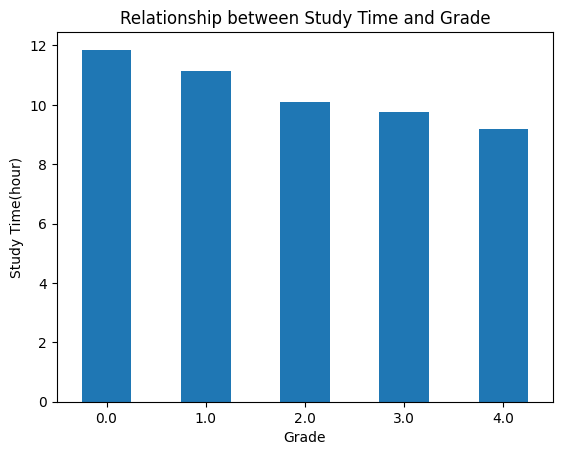

In [362]:
Study_Time.plot(kind="bar")
plt.title("Relationship between Study Time and Grade")
plt.xlabel("Grade")
plt.ylabel("Study Time")
plt.xticks(rotation=0)
plt.show()

The study time weekly does affect the grade of student. Student that spend more time in study per week gain better grade(0 = A , 1 = B , 2 = C , 3 = D , 4 = F ).